In [2]:
!pip install spacy scikit-learn pandas
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 32.8 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [17]:
from google.colab import files
files.upload()

Saving Elquijote.txt to Elquijote (1).txt


{'Elquijote (1).txt': b'Don Quijote de la mancha:\r\n\r\nAL DUQUE DE B\xc3\x89JAR,\r\n\r\nmarqu\xc3\xa9s de Gibrale\xc3\xb3n, conde de Benalc\xc3\xa1zar y Ba\xc3\xb1ares, vizconde de La Puebla de\r\nAlcocer, se\xc3\xb1or de las villas de Capilla, Curiel y Burguillos\r\n\r\nEn fe del buen acogimiento y honra que hace Vuestra Excelencia a toda\r\nsuerte de libros, como pr\xc3\xadncipe tan inclinado a favorecer las buenas artes,\r\nmayormente las que por su nobleza no se abaten al servicio y granjer\xc3\xadas del\r\nvulgo, he determinado de sacar a luz al Ingenioso hidalgo don Quijote de la\r\nMancha, al abrigo del clar\xc3\xadsimo nombre de Vuestra Excelencia, a quien, con\r\nel acatamiento que debo a tanta grandeza, suplico le reciba agradablemente\r\nen su protecci\xc3\xb3n, para que a su sombra, aunque desnudo de aquel precioso\r\nornamento de elegancia y erudici\xc3\xb3n de que suelen andar vestidas las obras\r\nque se componen en las casas de los hombres que saben, ose parecer\r\nse

In [11]:
import spacy

# Cargar modelo ahora en español
try:
    nlp = spacy.load("es_core_news_sm")
except OSError:
    print("Descargando modelo...")
    from spacy.cli import download
    download("es_core_news_sm")
    nlp = spacy.load("es_core_news_sm")

# TEXTO DE ENTRADA
with open("/content/Elquijote.txt", "r", encoding="utf-8") as f:
    texto_quijote = f.read()

# Ahora 'texto_quijote' contiene todo el texto del archivo
print(f"Texto cargado con éxito. Longitud: {len(texto_quijote)} caracteres.")

# 1. TOKENIZACIÓN
# SpaCy procesa el texto y crea el objeto 'doc' lleno de metadatos
doc = nlp(texto_quijote)

# Mostrar los primeros 15 tokens para entender cómo "ve" la máquina el texto
print(f"--- 1. Tokenización (Total tokens: {len(doc)}) ---")
print([token.text for token in doc][:20])

Texto cargado con éxito. Longitud: 9492 caracteres.
--- 1. Tokenización (Total tokens: 2083) ---
['Don', 'Quijote', 'de', 'la', 'mancha', ':', '\n\n', 'AL', 'DUQUE', 'DE', 'BÉJAR', ',', '\n\n', 'marqués', 'de', 'Gibraleón', ',', 'conde', 'de', 'Benalcázar']


In [12]:
# 2. FILTRADO DE STOP WORDS
# Separamos lo que aporta valor semántico del "pegamento" gramatical

tokens_relevantes = []
tokens_ruido = []

for token in doc:
    # Filtramos si es stopword o si es puntuación
    if not token.is_stop and not token.is_punct and token.text.strip():
        tokens_relevantes.append(token.text)
    elif token.is_stop:
        tokens_ruido.append(token.text)

print(f"\n--- 2. Filtrado de Stop Words ---")
print(f"Palabras eliminadas (Ruido): {tokens_ruido[:10]}...")
print(f"Palabras conservadas (Contenido): {tokens_relevantes[:10]}...")
print(f"Reducción de tamaño: de {len(doc)} a {len(tokens_relevantes)} tokens.")


--- 2. Filtrado de Stop Words ---
Palabras eliminadas (Ruido): ['de', 'la', 'AL', 'DE', 'de', 'de', 'y', 'de', 'La', 'de']...
Palabras conservadas (Contenido): ['Don', 'Quijote', 'mancha', 'DUQUE', 'BÉJAR', 'marqués', 'Gibraleón', 'conde', 'Benalcázar', 'Bañares']...
Reducción de tamaño: de 2083 a 671 tokens.


In [13]:
# 3. LEMATIZACIÓN Y NORMALIZACIÓN FINAL
# Reducimos las palabras a su raíz (Lema) y estandarizamos a minúsculas
# Objetivo: Que "hablo", "hablaré" y "habla" cuenten como el mismo concepto: "hablar"

tokens_normalizados = []
cambios_interesantes = []

for token in doc:
    # Aplicamos los mismos filtros de calidad que en el paso 2
    if not token.is_stop and not token.is_punct and token.text.strip():

        # AQUÍ OCURRE LA MAGIA:
        # 1. Extraemos el lema (token.lemma_)
        # 2. Convertimos a minúsculas (.lower())
        lema = token.lemma_.lower()
        tokens_normalizados.append(lema)

        # Para fines educativos: Guardamos casos donde la palabra cambió drásticamente
        # Ej: "fui" -> "ir"
        if token.text.lower() != lema:
            cambios_interesantes.append(f"{token.text} ➡ {lema}")

print(f"\n--- 3. Lematización y Normalización ---")
print(f"Total de tokens procesados: {len(tokens_normalizados)}")
print(f"Ejemplos de transformaciones (Palabra original ➡ Lema):")
# Mostramos solo los primeros 5 cambios para no saturar la pantalla
print(cambios_interesantes[:10])

print(f"\nResultado final (Primeros 10 tokens):")
print(tokens_normalizados[:10])


--- 3. Lematización y Normalización ---
Total de tokens procesados: 671
Ejemplos de transformaciones (Palabra original ➡ Lema):
['conde ➡ condir', 'vizconde ➡ vizcondar', 'villas ➡ villa', 'honra ➡ honrar', 'libros ➡ libro', 'artes ➡ art', 'abaten ➡ abatar', 'granjerías ➡ granjería', 'determinado ➡ determinar', 'tanta ➡ tanto']

Resultado final (Primeros 10 tokens):
['don', 'quijote', 'mancha', 'duque', 'béjar', 'marqués', 'gibraleón', 'condir', 'benalcázar', 'bañares']


In [15]:
!pip install nltk

In [ ]:
import pandas as pd
from nltk.stem import SnowballStemmer

# Configuración del Stemmer (NLTK)
stemmer = SnowballStemmer("spanish")
# Comparativa lado a lado
data_comparativa = []

for token in doc:
    # Solo analizamos palabras, ignoramos puntuación y espacios para claridad
    if not token.is_punct and not token.is_space:

        # A. STEMMING (Corte de sufijos)
        raiz_stem = stemmer.stem(token.text)

        # B. LEMATIZACIÓN (Análisis morfológico de SpaCy)
        # Nota: SpaCy usa el contexto para saber si 'fui' es 'ir' o 'ser'
        lema = token.lemma_

        data_comparativa.append({
            "Original": token.text,
            "Stemming (Corte)": raiz_stem,
            "Lematización (Diccionario)": lema,
            "¿Coinciden?": raiz_stem == lema
        })

# Crear DataFrame para visualizar
df = pd.DataFrame(data_comparativa)

print(f"\n--- 3. Stemming vs Lematización ---")
# Mostramos palabras interesantes donde se vea la diferencia
# Buscamos verbos conjugados o plurales
palabras_interesantes = ["hombres", "olvidado", "eres", "domesticado", "invisible", "ojos"]
filtro = df[df["Original"].isin(palabras_interesantes)]

print(filtro.to_string(index=False))

print("\n--- Visualización completa de los primeros 10 tokens ---")
print(df.head(10).to_string(index=False))

In [28]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [30]:
corpus_lematizado = []
for oracion in doc.sents:
    lemas_oracion = [
        token.lemma_.lower()
        for token in oracion
        if not token.is_punct and not token.is_space and not token.is_stop
    ]
    if lemas_oracion:
        corpus_lematizado.append(" ".join(lemas_oracion))

print(f"Total de oraciones procesadas: {len(corpus_lematizado)}")

Total de oraciones procesadas: 33


In [32]:
# Para Bag of Words
bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(corpus_lematizado)

In [33]:
# Para TF-IDF
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus_lematizado)

In [36]:
print(X_bow)
print(X_tfidf)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 662 stored elements and shape (33, 513)>
  Coords	Values
  (0, 172)	2
  (0, 415)	2
  (0, 310)	2
  (0, 175)	1
  (0, 66)	1
  (0, 318)	1
  (0, 233)	1
  (0, 100)	1
  (0, 62)	1
  (0, 61)	1
  (0, 501)	1
  (0, 407)	1
  (0, 27)	1
  (0, 448)	1
  (0, 500)	1
  (0, 75)	1
  (0, 124)	1
  (0, 64)	1
  (0, 223)	1
  (0, 8)	1
  (0, 259)	1
  (0, 217)	3
  (0, 460)	1
  (0, 296)	1
  (0, 405)	1
  :	:
  (30, 234)	1
  (30, 213)	1
  (31, 133)	1
  (31, 82)	1
  (31, 128)	1
  (31, 106)	1
  (31, 59)	1
  (31, 191)	1
  (31, 508)	1
  (31, 334)	1
  (31, 240)	1
  (32, 448)	1
  (32, 512)	1
  (32, 304)	1
  (32, 35)	1
  (32, 323)	1
  (32, 240)	1
  (32, 9)	1
  (32, 137)	1
  (32, 247)	1
  (32, 195)	1
  (32, 311)	1
  (32, 194)	1
  (32, 324)	1
  (32, 289)	1
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 662 stored elements and shape (33, 513)>
  Coords	Values
  (0, 172)	0.1465159539144996
  (0, 415)	0.1465159539144996
  (0, 310)	0.18365377340110578
  (0,

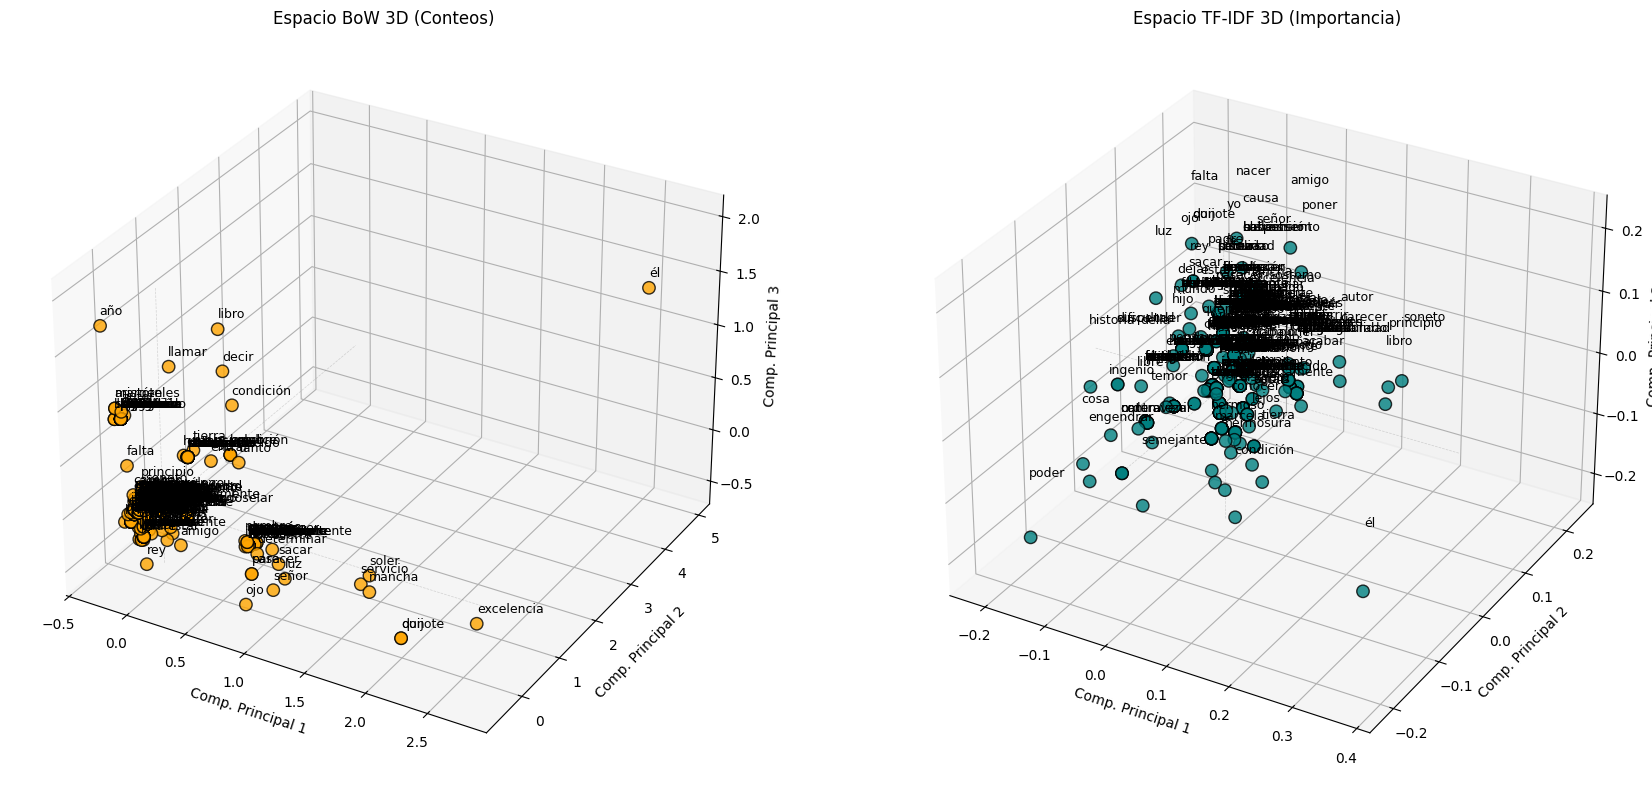

In [37]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D # Import necesario para 3D
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np

# ---------------------------------------------------------
# FUNCIÓN AUXILIAR PARA GRAFICAR EN 3D
# ---------------------------------------------------------
def graficar_palabras_3d(ax, matriz, vocabulario, titulo, color_puntos):
    # 1. TRANSPONER: Filas = Palabras, Columnas = Contextos
    matriz_palabras = matriz.T

    # 2. PCA: Reducir a 3 DIMENSIONES
    pca = PCA(n_components=3)
    coords = pca.fit_transform(matriz_palabras.toarray())

    # Extraer coordenadas X, Y, Z
    x = coords[:, 0]
    y = coords[:, 1]
    z = coords[:, 2]

    # 3. GRAFICAR SCATTER 3D
    # Usamos profundidad visual (depthshade=True) para ayudar a la perspectiva
    ax.scatter(x, y, z, c=color_puntos, s=80, edgecolors='k', alpha=0.8, depthshade=True)

    # Etiquetar puntos
    for i, palabra in enumerate(vocabulario):
        # Agregamos un pequeño offset a Z para que el texto flote sobre el punto
        ax.text(x[i], y[i], z[i] + 0.1, palabra, fontsize=9)

    ax.set_title(titulo)
    ax.set_xlabel('Comp. Principal 1')
    ax.set_ylabel('Comp. Principal 2')
    ax.set_zlabel('Comp. Principal 3')

    # Líneas de referencia en el origen (0,0,0)
    ax.plot([0,0], [0,0], [z.min(), z.max()], c='grey', ls='--', lw=0.5, alpha=0.3)
    ax.plot([x.min(), x.max()], [0,0], [0,0], c='grey', ls='--', lw=0.5, alpha=0.3)
    ax.plot([0,0], [y.min(), y.max()], [0,0], c='grey', ls='--', lw=0.5, alpha=0.3)


# ---------------------------------------------------------
# CONFIGURACIÓN DE LA FIGURA 3D
# ---------------------------------------------------------
# Creamos una figura ancha para poner dos gráficos lado a lado
fig = plt.figure(figsize=(18, 8))

# --- A. BAG OF WORDS (Izquierda) ---
# subplot(filas, columnas, índice, proyección)
ax1 = fig.add_subplot(121, projection='3d')

bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(corpus_lematizado)
vocab_bow = bow_vectorizer.get_feature_names_out()

graficar_palabras_3d(ax1, X_bow, vocab_bow,
                     "Espacio BoW 3D (Conteos)",
                     "orange")

# --- B. TF-IDF (Derecha) ---
ax2 = fig.add_subplot(122, projection='3d')

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus_lematizado)
vocab_tfidf = tfidf_vectorizer.get_feature_names_out()

graficar_palabras_3d(ax2, X_tfidf, vocab_tfidf,
                     "Espacio TF-IDF 3D (Importancia)",
                     "teal")

plt.tight_layout()
plt.show()

In [40]:
!pip install gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 45.7 MB/s  0:00:00


Procesando texto con SpaCy...
Total de oraciones procesadas: 33
Ejemplo (tokens): ['don', 'quijote', 'mancha', 'duque', 'béjar', 'marqués', 'gibraleón', 'condir', 'benalcázar', 'bañares', 'vizcondar', 'puebla', 'alcocer', 'señor', 'villa', 'capilla', 'curiel', 'burguillos', 'fe', 'acogimiento', 'honrar', 'excelencia', 'suerte', 'libro', 'príncipe', 'inclinado', 'favorecer', 'art', 'mayormente', 'nobleza', 'abatar', 'servicio', 'granjería', 'vulgo', 'determinar', 'sacar', 'luz', 'ingenioso', 'hidalgo', 'don', 'quijote', 'mancha', 'abrigo', 'clarísimo', 'nombre', 'excelencia', 'acatamiento', 'debo', 'tanto', 'grandeza', 'suplico', 'recibir', 'agradablemente', 'protección', 'sombra', 'desnudo', 'precioso', 'ornamento', 'elegancia', 'erudición', 'soler', 'andar', 'vestido', 'obra', 'componer', 'casa', 'hombre', 'o él', 'parecer', 'seguramente', 'juicio', 'contener él', 'límite', 'ignorancia', 'soler', 'condenar', 'rigor', 'justicia', 'trabajo', 'ajeno', 'poner', 'ojo', 'prudencia', 'excele

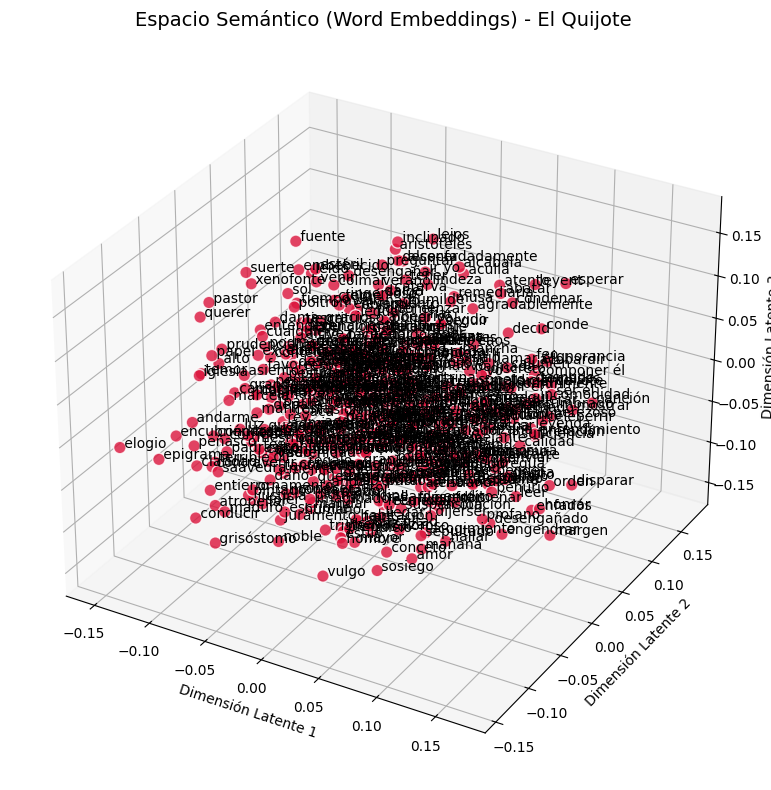


Así ve la máquina la palabra 'rey' (Vector de 10 dimensiones):
[ 0.04168826 -0.08869959 -0.06080883 -0.06516449  0.06699548 -0.08962133
 -0.01425767  0.01767472  0.00312612  0.03609173]


In [48]:
import pandas as pd
import spacy
from gensim.models import Word2Vec
import multiprocessing
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import numpy as np

# 1. PREPARACIÓN DE DATOS
nlp = spacy.load("es_core_news_sm")

with open("/content/Elquijote.txt", "r", encoding="utf-8") as f:
     texto_quijote = f.read()


print("Procesando texto con SpaCy...")
doc = nlp(texto_quijote)

sentences = []
for sent in doc.sents:
    # Lematizamos y quitamos stop words para reducir ruido
    tokens = [
        token.lemma_.lower()
        for token in sent
        if not token.is_stop and not token.is_punct and token.text.strip()
    ]
    if len(tokens) > 1: # Solo oraciones con algo de contenido
        sentences.append(tokens)

print(f"Total de oraciones procesadas: {len(sentences)}")
print(f"Ejemplo (tokens): {sentences[0]}")

# 2. ENTRENAMIENTO DE WORD2VEC
# Creamos vectores densos (Embeddings)
print("\nEntrenando red neuronal Word2Vec...")

model = Word2Vec(
    sentences,
    vector_size=10,  # 10 dimensiones (neuronas en la capa oculta)
    window=5,        # Contexto
    min_count=1,     # Aceptamos palabras únicas por ser un dataset mini
    workers=multiprocessing.cpu_count(),
    seed=42          # Semilla para reproducibilidad
)

# 3. EXPLORACIÓN SEMÁNTICA
def mostrar_similares(palabra):
    try:
        # topn=3 nos da las 3 palabras más cercanas en el espacio vectorial
        similares = model.wv.most_similar(palabra, topn=3)
        print(f"\nPalabras más cercanas semánticamente a '{palabra}':")
        for sim in similares:
            # sim es una tupla (palabra, puntuación)
            print(f"  - {sim[0]} (Similitud: {sim[1]:.4f})")
    except KeyError:
        print(f"\nLa palabra '{palabra}' no está en el vocabulario.")

# Probamos conceptos (Nota: con texto tan corto, las asociaciones serán raras)
mostrar_similares("conde")
mostrar_similares("noble")

# 4. VISUALIZACIÓN 3D (PCA de Embeddings)
# Aquí ocurre la magia: proyectamos las 10 dimensiones a 3 para verlas.

# Obtenemos todas las palabras y sus vectores
vocabulario = list(model.wv.index_to_key)
vectores = model.wv[vocabulario]

# Reducción de dimensionalidad
pca = PCA(n_components=3)
vectores_3d = pca.fit_transform(vectores)

# Crear DataFrame para facilitar ploteo
df_3d = pd.DataFrame(vectores_3d, columns=['x', 'y', 'z'])
df_3d['palabra'] = vocabulario

# Gráfico
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df_3d['x'], df_3d['y'], df_3d['z'], c='crimson', s=80, edgecolors='white', alpha=0.8)

# Etiquetas
for i, row in df_3d.iterrows():
    ax.text(row['x'], row['y'], row['z'], f" {row['palabra']}", size=10)

ax.set_title('Espacio Semántico (Word Embeddings) - El Quijote', fontsize=14)
ax.set_xlabel('Dimensión Latente 1')
ax.set_ylabel('Dimensión Latente 2')
ax.set_zlabel('Dimensión Latente 3')

plt.tight_layout()
plt.show()

print(f"\nAsí ve la máquina la palabra 'rey' (Vector de 10 dimensiones):")
try:
    print(model.wv["rey"])
except:
    print("La palabra no apareció en el texto, intenta con 'rey'.")